# Bath correlation: model, OQuPy, and QuTiP

Our model is
$$J(\omega)=\alpha\,\omega^s\omega_c^{1-s}e^{-\omega/\omega_c},\qquad
C(t)=\int_0^\infty J(\omega)\left[\coth\!\left(\frac{\beta\omega}{2}\right)\cos(\omega t)+i\sin(\omega t)\right]d\omega.$$
At $T=0$, the analytic correlation in the stated $e^{+i\omega t}$ convention is
$$C_0(t)=\frac{\alpha\omega_c^{1-s}\,\Gamma(s+1)}{(\omega_c^{-1}+it)^{s+1}}.$$

| Parameter | Matching value | Package convention |
|---|---|---|
| Model | $\alpha$ | $J=\alpha\omega^s\omega_c^{1-s} e^{-\omega/\omega_c}$ |
| OQuPy | $\alpha_{\rm OQ}=\alpha/2$ | `PowerLawSD` has $J_{\rm OQ}=2\alpha_{\rm OQ}\omega^s\omega_c^{1-s}e^{-\omega/\omega_c}$ |
| QuTiP | $\alpha_{\rm QT}=\pi\alpha$ | `OhmicEnvironment` has $J_{\rm QT}=\alpha_{\rm QT}\omega^s\omega_c^{1-s}e^{-\omega/\omega_c}$; its $C(t)$ integral includes $1/\pi$ |

Thus for $s=1$, $\alpha_{\rm OQ}=\alpha/2$ and $\alpha_{\rm QT}=\pi\alpha$. The suggested `alpha=np.pi*alpha` for QuTiP would match a model whose $J$ coefficient is $2\alpha$, not $2\pi\alpha$. Both libraries return the opposite time-ordering sign to the model's zero-temperature $e^{+i\omega t}$ expression, so the code conjugates their correlations. The finite-$T$ formula above has $-i\sin(\omega t)$, whose $T\to0$ limit is $e^{-i\omega t}$; choose one sign convention consistently in an application.

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma
import oqupy
import qutip

# Set the physical model parameters (hbar = k_B = 1).
alpha = 0.1
omega_c = 5.0
temperature = 0.0

def J_model(omega):
    omega = np.asarray(omega)
    return alpha * omega * np.exp(-omega / omega_c)

def C_analytic_zero_temperature(t):
    return (
        alpha * gamma(s + 1.0)
        / (1.0 / omega_c + 1j * np.asarray(t)) ** 2.0
    )

validation_frequencies = np.linspace(0.0, 8.0 * omega_c, 400)
validation_times = np.linspace(0.0, 4.0 / omega_c, 100)
J_model_values = J_model(validation_frequencies)

alpha_model=0.1, alpha_OQ=0.05, alpha_QT=0.314159
max |J_OQuPy - J_model|: 0.0
max |J_QuTiP/pi - J_model|: 2.7755575615628914e-17
max |C_OQuPy - C_analytic|: 1.9041140906959176e-10
max |C_QuTiP - C_analytic|: 6.661338147750939e-16
max |C_QuTiP - C_OQuPy|: 1.9041142294737957e-10


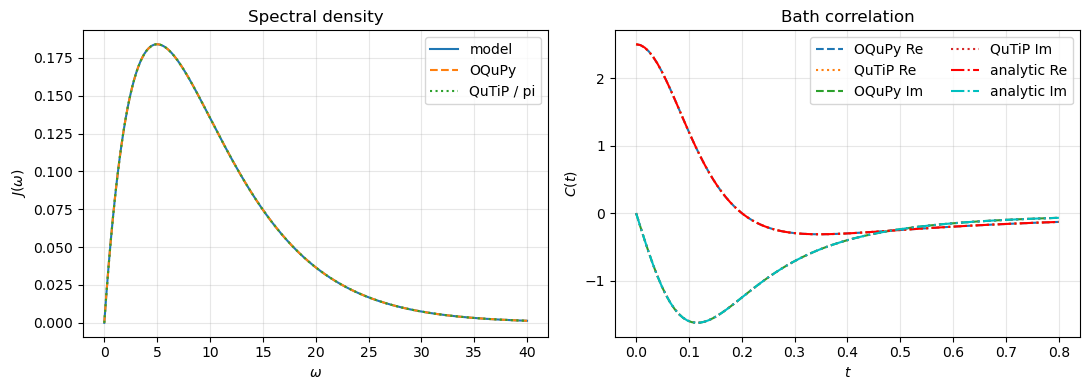

In [32]:
# OQuPy correlation object, using its matching alpha convention.
alpha_oqupy = alpha / 2.0
correlations = oqupy.PowerLawSD(
    alpha=alpha_oqupy,
    zeta=s,
    cutoff=omega_c,
    cutoff_type="exponential",
    temperature=temperature,
)
J_oqupy = np.asarray(correlations.spectral_density(validation_frequencies))
C_oqupy = np.array([correlations.correlation(t) for t in validation_times])

# Direct QuTiP OhmicEnvironment: no numeric spectral-density fit is used.
alpha_qutip = np.pi * alpha
environment = qutip.OhmicEnvironment(
    T=temperature,
    alpha=alpha_qutip,
    wc=omega_c,
    s=s,
)
J_qutip_as_model = np.asarray(
    environment.spectral_density(validation_frequencies)
) / np.pi
C_qutip = np.asarray(environment.correlation_function(validation_times))

print(f"alpha_model={alpha:g}, alpha_OQ={alpha_oqupy:g}, alpha_QT={alpha_qutip:g}")
print("max |J_OQuPy - J_model|:", np.max(np.abs(J_oqupy - J_model_values)))
print("max |J_QuTiP/pi - J_model|:", np.max(np.abs(J_qutip_as_model - J_model_values)))
if temperature == 0.0:
    C_exact = C_analytic_zero_temperature(validation_times)
    print("max |C_OQuPy - C_analytic|:", np.max(np.abs(C_oqupy - C_exact)))
    print("max |C_QuTiP - C_analytic|:", np.max(np.abs(C_qutip - C_exact)))
    print("max |C_QuTiP - C_OQuPy|:", np.max(np.abs(C_qutip - C_oqupy)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(validation_frequencies, J_model_values, label="model")
axes[0].plot(validation_frequencies, J_oqupy, "--", label="OQuPy")
axes[0].plot(validation_frequencies, J_qutip_as_model, ":", label="QuTiP / pi")
axes[0].set(xlabel=r"$\omega$", ylabel=r"$J(\omega)$", title="Spectral density")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(validation_times, C_oqupy.real, "--", label="OQuPy Re")
axes[1].plot(validation_times, C_qutip.real, ":", label="QuTiP Re")
axes[1].plot(validation_times, C_oqupy.imag, "--", label="OQuPy Im")
axes[1].plot(validation_times, C_qutip.imag, ":", label="QuTiP Im")
if temperature == 0.0:
    axes[1].plot(validation_times, C_exact.real, "-.", color="r", label="analytic Re")
    axes[1].plot(validation_times, C_exact.imag, "-.", color="c", label="analytic Im")
axes[1].set(xlabel=r"$t$", ylabel=r"$C(t)$", title="Bath correlation")
axes[1].legend(ncol=2)
axes[1].grid(alpha=0.3)
plt.tight_layout()

`OhmicEnvironment` evaluates its parameterized correlation directly. This avoids numerical construction of $J(\omega)$ and an exponential fit. If you later run the HEOM solver, an exponential decomposition may still be needed by the solver; that is separate from evaluating and plotting `environment.correlation_function(...)`.